# Section 1


In [ ]:
# ==========================================================
# Section 1: Environment Setup
# Cell 1: Import Required Libraries
# ==========================================================

import os
import random
import warnings
import joblib
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Progress Bar
from tqdm.auto import tqdm

In [ ]:
# ==========================================================
# Cell 2: Reproducibility & Device Configuration
# ==========================================================

SEED = 42

# Python
random.seed(SEED)

# NumPy
np.random.seed(SEED)

# PyTorch
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Device Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 50)
print(f"Using Device : {device}")

if torch.cuda.is_available():
    print(f"GPU Name     : {torch.cuda.get_device_name(0)}")

print("=" * 50)

Using Device : cuda
GPU Name     : Tesla T4


In [ ]:
# ==========================================================
# Cell 3: Project Paths
# ==========================================================

PROJECT_ROOT = "/content/drive/MyDrive/Major_Project"

ENGINEERED_DATASET_PATH = f"{PROJECT_ROOT}/dataset/engineered/engineered_dataset.pkl"

MODEL_DIR = f"{PROJECT_ROOT}/models"

os.makedirs(MODEL_DIR, exist_ok=True)

print("=" * 60)
print("Project Root :", PROJECT_ROOT)
print("Dataset Path :", ENGINEERED_DATASET_PATH)
print("Model Path   :", MODEL_DIR)
print("=" * 60)

Project Root : /content/drive/MyDrive/Major_Project
Dataset Path : /content/drive/MyDrive/Major_Project/dataset/engineered/engineered_dataset.pkl
Model Path   : /content/drive/MyDrive/Major_Project/models


# Section 2

In [ ]:
# ==========================================================
# Section 2: Load Engineered Dataset
# Cell 1: Load Engineered Dataset
# ==========================================================

print("Loading engineered dataset...\n")

df = pd.read_pickle(ENGINEERED_DATASET_PATH)

print("Dataset loaded successfully.")
print(f"Dataset Shape: {df.shape}")

Loading engineered dataset...

Dataset loaded successfully.
Dataset Shape: (3384445, 49)


In [ ]:
# ==========================================================
# Cell 2: Dataset Verification
# ==========================================================

print("=" * 60)
print("Dataset Information")
print("=" * 60)

print(f"Shape              : {df.shape}")
print(f"Memory Usage (MB)  : {df.memory_usage(deep=True).sum() / (1024**2):.2f}")

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nFirst Five Rows:")
display(df.head())

Dataset Information
Shape              : (3384445, 49)
Memory Usage (MB)  : 1419.07

Column Names:
['Flow Duration_Mean', 'Flow Duration_Std', 'Flow Duration_Variance', 'Flow Duration_Min', 'Flow Duration_Max', 'Flow Duration_Renyi', 'Flow Bytes/s_Mean', 'Flow Bytes/s_Std', 'Flow Bytes/s_Variance', 'Flow Bytes/s_Min', 'Flow Bytes/s_Max', 'Flow Bytes/s_Renyi', 'Flow Packets/s_Mean', 'Flow Packets/s_Std', 'Flow Packets/s_Variance', 'Flow Packets/s_Min', 'Flow Packets/s_Max', 'Flow Packets/s_Renyi', 'Packet Length Mean_Mean', 'Packet Length Mean_Std', 'Packet Length Mean_Variance', 'Packet Length Mean_Min', 'Packet Length Mean_Max', 'Packet Length Mean_Renyi', 'Packet Length Std_Mean', 'Packet Length Std_Std', 'Packet Length Std_Variance', 'Packet Length Std_Min', 'Packet Length Std_Max', 'Packet Length Std_Renyi', 'Total Fwd Packets_Mean', 'Total Fwd Packets_Std', 'Total Fwd Packets_Variance', 'Total Fwd Packets_Min', 'Total Fwd Packets_Max', 'Total Fwd Packets_Renyi', 'Total Backward Pa

,Flow Duration_Mean,Flow Duration_Std,Flow Duration_Variance,Flow Duration_Min,Flow Duration_Max,Flow Duration_Renyi,Flow Bytes/s_Mean,Flow Bytes/s_Std,Flow Bytes/s_Variance,Flow Bytes/s_Min,...,Total Backward Packets_Min,Total Backward Packets_Max,Total Backward Packets_Renyi,Average Packet Size_Mean,Average Packet Size_Std,Average Packet Size_Variance,Average Packet Size_Min,Average Packet Size_Max,Average Packet Size_Renyi,Label
0,10839530.69,2.843003e+07,8.082669e+14,1,119842965,0.595533,333457.721947,3.083312e+06,9.506815e+12,0.0,...,0,96,0.787368,119.622965,223.877889,50121.309327,0.0,1533.777778,1.270904,BENIGN
1,10505891.36,2.883378e+07,8.313870e+14,96,118514337,0.525330,42053.922346,2.446347e+05,5.984614e+10,0.0,...,0,201,0.696190,184.627261,317.521456,100819.875155,0.0,1784.444444,1.225666,BENIGN
2,12329517.29,3.187952e+07,1.016304e+15,97,118759341,0.586406,65741.641517,2.704786e+05,7.315865e+10,0.0,...,0,260,0.903468,252.496307,416.828398,173745.913406,0.0,1784.444444,1.502260,BENIGN
3,15855919.38,3.638650e+07,1.323977e+15,1,118759341,0.681770,376029.512487,3.089682e+06,9.546132e+12,0.0,...,0,260,1.081308,251.265778,418.410308,175067.185685,0.0,1784.444444,1.682233,BENIGN
4,15815469.62,3.650741e+07,1.332791e+15,1,118759341,0.647016,376991.772878,3.089569e+06,9.545437e+12,0.0,...,0,260,1.043943,254.374859,416.931181,173831.609710,0.0,1784.444444,1.531156,BENIGN


# Section 3

In [ ]:
# ==========================================================
# Section 3: Data Preparation
# Cell 1: Inspect Target Variable
# ==========================================================

print("=" * 60)
print("Target Variable Information")
print("=" * 60)

print(f"Label Data Type : {df['Label'].dtype}")

print("\nUnique Classes:")
print(df["Label"].unique())

print("\nClass Distribution:")
print(df["Label"].value_counts())

Target Variable Information
Label Data Type : object

Unique Classes:
['BENIGN' 'DrDoS_NTP' 'Syn' 'LDAP' 'MSSQL' 'DrDoS_DNS' 'TFTP' 'UDP'
 'UDPLag' 'UDP-lag' 'NetBIOS' 'DrDoS_SSDP' 'DrDoS_NetBIOS' 'Portmap'
 'DrDoS_MSSQL' 'DrDoS_UDP' 'DrDoS_LDAP' 'DrDoS_SNMP']

Class Distribution:
Label
TFTP             973647
MSSQL            278897
Syn              274387
DrDoS_SNMP       257105
DrDoS_DNS        245125
DrDoS_MSSQL      219509
DrDoS_NetBIOS    197920
UDP              189301
NetBIOS          175580
DrDoS_UDP        154527
DrDoS_SSDP       128258
DrDoS_LDAP       106972
LDAP              93552
DrDoS_NTP         59660
UDP-lag           16500
Portmap            8835
BENIGN             4578
UDPLag               92
Name: count, dtype: int64


In [ ]:
# ==========================================================
# Cell 2: Standardize & Encode Labels
# ==========================================================

from sklearn.preprocessing import LabelEncoder

# Standardize inconsistent class names
df["Label"] = df["Label"].replace({
    "UDPLag": "UDP-lag"
})

# Initialize Label Encoder
label_encoder = LabelEncoder()

# Encode labels
df["Label"] = label_encoder.fit_transform(df["Label"])

# Save Label Encoder
joblib.dump(label_encoder, f"{MODEL_DIR}/label_encoder.pkl")

print("=" * 60)
print("Label Encoding Completed")
print("=" * 60)

print(f"Number of Classes : {len(label_encoder.classes_)}")

print("\nClass Mapping:")

for index, label in enumerate(label_encoder.classes_):
    print(f"{index:2d} --> {label}")

Label Encoding Completed
Number of Classes : 17

Class Mapping:
 0 --> BENIGN
 1 --> DrDoS_DNS
 2 --> DrDoS_LDAP
 3 --> DrDoS_MSSQL
 4 --> DrDoS_NTP
 5 --> DrDoS_NetBIOS
 6 --> DrDoS_SNMP
 7 --> DrDoS_SSDP
 8 --> DrDoS_UDP
 9 --> LDAP
10 --> MSSQL
11 --> NetBIOS
12 --> Portmap
13 --> Syn
14 --> TFTP
15 --> UDP
16 --> UDP-lag


In [ ]:
# ==========================================================
# Cell 3: Separate Features and Target
# ==========================================================

# Separate Features and Target
X = df.drop(columns=["Label"])
y = df["Label"]

print("=" * 60)
print("Feature Matrix Shape :", X.shape)
print("Target Vector Shape  :", y.shape)
print("=" * 60)

Feature Matrix Shape : (3384445, 48)
Target Vector Shape  : (3384445,)


In [ ]:
# ==========================================================
# Cell 4: Train / Validation / Test Split
# ==========================================================

# First Split: 80% Train | 20% Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

# Second Split: 10% Validation | 10% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

print("=" * 60)
print("Dataset Split Completed")
print("=" * 60)

print(f"Training Set   : {X_train.shape}")
print(f"Validation Set : {X_val.shape}")
print(f"Test Set       : {X_test.shape}")

Dataset Split Completed
Training Set   : (2707556, 48)
Validation Set : (338444, 48)
Test Set       : (338445, 48)


In [ ]:
# ==========================================================
# Cell 5: Feature Scaling
# ==========================================================

print("Initializing StandardScaler...")

scaler = StandardScaler()

print("Fitting scaler on training data...")
X_train = scaler.fit_transform(X_train)

print("Transforming validation data...")
X_val = scaler.transform(X_val)

print("Transforming test data...")
X_test = scaler.transform(X_test)

# Save the fitted scaler
joblib.dump(scaler, f"{MODEL_DIR}/scaler.pkl")

print("\n" + "=" * 60)
print("Feature Scaling Completed Successfully")
print("=" * 60)

print(f"Training Set   : {X_train.shape}")
print(f"Validation Set : {X_val.shape}")
print(f"Test Set       : {X_test.shape}")

print("\nScaler saved to:")
print(f"{MODEL_DIR}/scaler.pkl")

Initializing StandardScaler...
Fitting scaler on training data...
Transforming validation data...
Transforming test data...

Feature Scaling Completed Successfully
Training Set   : (2707556, 48)
Validation Set : (338444, 48)
Test Set       : (338445, 48)

Scaler saved to:
/content/drive/MyDrive/Major_Project/models/scaler.pkl


# Section 4


In [ ]:
# ==========================================================
# Section 4: PyTorch Dataset
# Cell 1: Custom Dataset Class (Final)
# ==========================================================

class DDoSDataset(Dataset):
    """
    Custom PyTorch Dataset for Hybrid CNN-BiLSTM-Attention Model.
    """

    def __init__(self, features, labels):
        self.features = features
        self.labels = labels

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):

        # Feature Tensor
        x = torch.tensor(self.features[idx], dtype=torch.float32)

        # Reshape for Conv1D
        # (48,) -> (1, 48)
        x = x.unsqueeze(0)

        # Label Tensor
        y = torch.tensor(self.labels[idx], dtype=torch.long)

        return x, y

In [ ]:
# ==========================================================
# Cell 2: Create Dataset Objects
# ==========================================================

train_dataset = DDoSDataset(X_train, y_train.values)
val_dataset   = DDoSDataset(X_val, y_val.values)
test_dataset  = DDoSDataset(X_test, y_test.values)

print("=" * 60)
print("Datasets Created Successfully")
print("=" * 60)

print(f"Training Samples   : {len(train_dataset):,}")
print(f"Validation Samples : {len(val_dataset):,}")
print(f"Test Samples       : {len(test_dataset):,}")

Datasets Created Successfully
Training Samples   : 2,707,556
Validation Samples : 338,444
Test Samples       : 338,445


In [ ]:
# ==========================================================
# Cell 3: Create DataLoaders
# ==========================================================

BATCH_SIZE = 512

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

print("=" * 60)
print("DataLoaders Created Successfully")
print("=" * 60)

print(f"Batch Size : {BATCH_SIZE}")

DataLoaders Created Successfully
Batch Size : 512


In [ ]:
# ==========================================================
# Cell 4: Verify DataLoader
# ==========================================================

X_batch, y_batch = next(iter(train_loader))

print("=" * 60)
print("Batch Verification")
print("=" * 60)

print(f"Feature Batch Shape : {X_batch.shape}")
print(f"Label Batch Shape   : {y_batch.shape}")

print(f"\nFeature Data Type : {X_batch.dtype}")
print(f"Label Data Type   : {y_batch.dtype}")

Batch Verification
Feature Batch Shape : torch.Size([512, 1, 48])
Label Batch Shape   : torch.Size([512])

Feature Data Type : torch.float32
Label Data Type   : torch.int64


# Section 5


In [ ]:
# ==========================================================
# Section 5: Hybrid CNN-BiLSTM-Attention
# Cell 1: Attention Module
# ==========================================================

class Attention(nn.Module):
    """
    Attention Layer for Bi-LSTM Outputs
    """

    def __init__(self, hidden_size):
        super(Attention, self).__init__()

        self.attention = nn.Linear(hidden_size * 2, 1)

    def forward(self, lstm_output):
        """
        lstm_output shape:
        (batch_size, sequence_length, hidden_size * 2)
        """

        # Compute attention scores
        scores = self.attention(lstm_output)

        # Normalize scores
        weights = torch.softmax(scores, dim=1)

        # Context Vector
        context = torch.sum(weights * lstm_output, dim=1)

        return context, weights

In [ ]:
# ==========================================================
# Cell 2: Hybrid CNN-BiLSTM-Attention Model
# ==========================================================

class HybridDDoSModel(nn.Module):
    """
    Hybrid CNN + BiLSTM + Attention Network
    """

    def __init__(self,
                 input_channels=1,
                 num_classes=17):

        super(HybridDDoSModel, self).__init__()

        # -----------------------------
        # CNN Feature Extractor
        # -----------------------------
        self.cnn = nn.Sequential(

            nn.Conv1d(
                in_channels=input_channels,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm1d(128),
            nn.ReLU()
        )

        # -----------------------------
        # Bi-LSTM
        # -----------------------------
        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        # -----------------------------
        # Attention
        # -----------------------------
        self.attention = Attention(hidden_size=128)

        # -----------------------------
        # Classifier
        # -----------------------------
        self.classifier = nn.Sequential(

            nn.Dropout(0.3),

            nn.Linear(256, 64),

            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        # CNN
        x = self.cnn(x)

        # CNN Output:
        # (batch, channels, sequence)

        # Convert to
        # (batch, sequence, channels)

        x = x.permute(0, 2, 1)

        # BiLSTM
        lstm_output, _ = self.lstm(x)

        # Attention
        context, attention_weights = self.attention(lstm_output)

        # Classification
        output = self.classifier(context)

        return output

In [ ]:
# ==========================================================
# Cell 3: Model Initialization & Verification
# ==========================================================

# Initialize Model
model = HybridDDoSModel(num_classes=17)

# Move Model to GPU
model = model.to(device)

print("=" * 60)
print("Model Initialized Successfully")
print("=" * 60)

print(model)

# ----------------------------------------------------------
# Verify One Forward Pass
# ----------------------------------------------------------

model.eval()

with torch.no_grad():

    sample_batch, sample_labels = next(iter(train_loader))

    sample_batch = sample_batch.to(device)

    outputs = model(sample_batch)

print("\n" + "=" * 60)
print("Forward Pass Successful")
print("=" * 60)

print(f"Input Shape  : {sample_batch.shape}")
print(f"Output Shape : {outputs.shape}")

Model Initialized Successfully
HybridDDoSModel(
  (cnn): Sequential(
    (0): Conv1d(1, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
  )
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (attention): Attention(
    (attention): Linear(in_features=256, out_features=1, bias=True)
  )
  (classifier): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=256, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=17, bias=True)
  )
)

Forward Pass Successful
Input Shape  : torch.Size([512, 1, 48])
Output Shape : torc

# Section 6


In [ ]:
# ==========================================================
# Section 6: Model Training
# Cell 1: Training Configuration
# ==========================================================

# PyTorch
import torch
import torch.nn as nn

# -----------------------------
# Training Hyperparameters
# -----------------------------

NUM_EPOCHS = 30

LEARNING_RATE = 1e-3

WEIGHT_DECAY = 1e-4

GRADIENT_CLIP_VALUE = 1.0

EARLY_STOPPING_PATIENCE = 5


# -----------------------------
# Loss Function
# -----------------------------

criterion = nn.CrossEntropyLoss()


# -----------------------------
# Optimizer
# -----------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# -----------------------------
# Learning Rate Scheduler
# -----------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)


# -----------------------------
# Mixed Precision
# -----------------------------

scaler_amp = torch.cuda.amp.GradScaler(
    enabled=torch.cuda.is_available()
)


# -----------------------------
# Training State
# -----------------------------

best_val_loss = float("inf")
epochs_without_improvement = 0


# -----------------------------
# Display Configuration
# -----------------------------

print("=" * 60)
print("Training Configuration")
print("=" * 60)

print(f"Device                  : {device}")
print(f"Epochs                  : {NUM_EPOCHS}")
print(f"Batch Size              : {BATCH_SIZE}")
print(f"Learning Rate           : {LEARNING_RATE}")
print(f"Weight Decay            : {WEIGHT_DECAY}")
print(f"Gradient Clip           : {GRADIENT_CLIP_VALUE}")
print(f"Early Stopping Patience : {EARLY_STOPPING_PATIENCE}")
print(f"Mixed Precision         : {torch.cuda.is_available()}")
print("=" * 60)

Training Configuration
Device                  : cuda
Epochs                  : 30
Batch Size              : 512
Learning Rate           : 0.001
Weight Decay            : 0.0001
Gradient Clip           : 1.0
Early Stopping Patience : 5
Mixed Precision         : True


In [ ]:
# ==========================================================
# Section 6: Model Training
# Cell 2: Training Function
# ==========================================================

def train_one_epoch(
    model,
    data_loader,
    criterion,
    optimizer,
    scaler_amp,
    device,
    gradient_clip_value
):
    """
    Train the model for one complete epoch.
    """

    model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    progress_bar = tqdm(
        data_loader,
        desc="Training",
        leave=False
    )

    for inputs, labels in progress_bar:

        # Move batch to GPU
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear previous gradients
        optimizer.zero_grad(set_to_none=True)

        # Mixed Precision Forward + Loss
        with torch.cuda.amp.autocast(
            enabled=torch.cuda.is_available()
        ):
            outputs = model(inputs)
            loss = criterion(outputs, labels)

        # Backpropagation
        scaler_amp.scale(loss).backward()

        # Unscale gradients before clipping
        scaler_amp.unscale_(optimizer)

        # Gradient Clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            gradient_clip_value
        )

        # Optimizer Step
        scaler_amp.step(optimizer)
        scaler_amp.update()

        # Statistics
        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size

        predictions = torch.argmax(outputs, dim=1)

        correct_predictions += (
            (predictions == labels).sum().item()
        )

        total_samples += batch_size

        # Update progress bar
        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = running_loss / total_samples
    epoch_accuracy = correct_predictions / total_samples

    return epoch_loss, epoch_accuracy

In [ ]:
# ==========================================================
# Section 6: Model Training
# Cell 3: Validation Function
# ==========================================================

def validate_one_epoch(
    model,
    data_loader,
    criterion,
    device
):
    """
    Evaluate the model for one complete validation epoch.
    """

    model.eval()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    progress_bar = tqdm(
        data_loader,
        desc="Validation",
        leave=False
    )

    with torch.no_grad():

        for inputs, labels in progress_bar:

            # Move batch to GPU
            inputs = inputs.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            # Mixed Precision Forward Pass
            with torch.cuda.amp.autocast(
                enabled=torch.cuda.is_available()
            ):
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            # Statistics
            batch_size = labels.size(0)

            running_loss += loss.item() * batch_size

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            correct_predictions += (
                (predictions == labels)
                .sum()
                .item()
            )

            total_samples += batch_size

            progress_bar.set_postfix(
                loss=f"{loss.item():.4f}"
            )

    epoch_loss = running_loss / total_samples

    epoch_accuracy = (
        correct_predictions / total_samples
    )

    return epoch_loss, epoch_accuracy

In [ ]:
# ==========================================================
# Section 6: Model Training
# Cell 4: Resume-Safe Training Loop
# ==========================================================

import os
import json

# ----------------------------------------------------------
# Paths
# ----------------------------------------------------------

BEST_MODEL_PATH = f"{MODEL_DIR}/hybrid_model.pth"

CHECKPOINT_PATH = f"{MODEL_DIR}/training_checkpoint.pth"

HISTORY_PATH = f"{MODEL_DIR}/training_history.json"


# ----------------------------------------------------------
# Initialize Training State
# ----------------------------------------------------------

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "learning_rate": []
}

best_val_loss = float("inf")
epochs_without_improvement = 0
start_epoch = 0


# ----------------------------------------------------------
# Resume From Checkpoint If Available
# ----------------------------------------------------------

if os.path.exists(CHECKPOINT_PATH):

    print("=" * 60)
    print("Training Checkpoint Found")
    print("=" * 60)

    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=device
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    scaler_amp.load_state_dict(
        checkpoint["scaler_state_dict"]
    )

    history = checkpoint["history"]

    best_val_loss = checkpoint["best_val_loss"]

    epochs_without_improvement = (
        checkpoint["epochs_without_improvement"]
    )

    start_epoch = checkpoint["epoch"] + 1

    print(
        f"Resuming from Epoch {start_epoch + 1}"
    )

else:

    print("=" * 60)
    print("Starting New Training Run")
    print("=" * 60)


# ----------------------------------------------------------
# Training Loop
# ----------------------------------------------------------

for epoch in range(start_epoch, NUM_EPOCHS):

    print(f"\nEpoch [{epoch + 1}/{NUM_EPOCHS}]")
    print("-" * 60)

    # -----------------------------
    # Training
    # -----------------------------

    train_loss, train_accuracy = train_one_epoch(
        model=model,
        data_loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        scaler_amp=scaler_amp,
        device=device,
        gradient_clip_value=GRADIENT_CLIP_VALUE
    )

    # -----------------------------
    # Validation
    # -----------------------------

    val_loss, val_accuracy = validate_one_epoch(
        model=model,
        data_loader=val_loader,
        criterion=criterion,
        device=device
    )

    # -----------------------------
    # Learning Rate Scheduler
    # -----------------------------

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    # -----------------------------
    # Store History
    # -----------------------------

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["learning_rate"].append(current_lr)

    # -----------------------------
    # Display Results
    # -----------------------------

    print(
        f"Train Loss : {train_loss:.4f} | "
        f"Train Acc : {train_accuracy:.4f}"
    )

    print(
        f"Val Loss   : {val_loss:.4f} | "
        f"Val Acc   : {val_accuracy:.4f}"
    )

    print(
        f"Learning Rate : {current_lr:.6f}"
    )

    # -----------------------------
    # Check for Improvement
    # -----------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        # Save best model
        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        print("✓ Best model saved.")

    else:

        epochs_without_improvement += 1

        print(
            f"No improvement "
            f"({epochs_without_improvement}/"
            f"{EARLY_STOPPING_PATIENCE})"
        )

    # ------------------------------------------------------
    # Save Training History After EVERY Epoch
    # ------------------------------------------------------

    with open(HISTORY_PATH, "w") as f:
        json.dump(history, f, indent=4)

    # ------------------------------------------------------
    # Save Full Resume Checkpoint After EVERY Epoch
    # ------------------------------------------------------

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler_amp.state_dict(),
            "history": history,
            "best_val_loss": best_val_loss,
            "epochs_without_improvement":
                epochs_without_improvement
        },
        CHECKPOINT_PATH
    )

    # -----------------------------
    # Early Stopping
    # -----------------------------

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:

        print("\nEarly stopping triggered.")

        break


print("\n" + "=" * 60)
print("Training Completed")
print("=" * 60)

print(f"Best Model Path : {BEST_MODEL_PATH}")
print(f"History Path    : {HISTORY_PATH}")
print(f"Checkpoint Path : {CHECKPOINT_PATH}")
print(f"Best Val Loss   : {best_val_loss:.4f}")
print(
    f"Best Val Accuracy : "
    f"{max(history['val_accuracy']) * 100:.2f}%"
)

Starting New Training Run

Epoch [1/30]
------------------------------------------------------------


Training:   0%|          | 0/5289 [00:00<?, ?it/s]

Validation:   0%|          | 0/662 [00:00<?, ?it/s]

Train Loss : 0.3282 | Train Acc : 0.8655
Val Loss   : 0.2873 | Val Acc   : 0.8766
Learning Rate : 0.001000
✓ Best model saved.

Epoch [2/30]
------------------------------------------------------------


Training:   0%|          | 0/5289 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/662 [00:00<?, ?it/s]

Train Loss : 0.2485 | Train Acc : 0.8956
Val Loss   : 0.2555 | Val Acc   : 0.8922
Learning Rate : 0.000250
No improvement (4/5)

Epoch [22/30]
------------------------------------------------------------


Training:   0%|          | 0/5289 [00:00<?, ?it/s]

Validation:   0%|          | 0/662 [00:00<?, ?it/s]

Train Loss : 0.2477 | Train Acc : 0.8960
Val Loss   : 0.3013 | Val Acc   : 0.8770
Learning Rate : 0.000250
No improvement (5/5)

Early stopping triggered.

Training Completed
Best Model Path : /content/drive/MyDrive/Major_Project/models/hybrid_model.pth
History Path    : /content/drive/MyDrive/Major_Project/models/training_history.json
Checkpoint Path : /content/drive/MyDrive/Major_Project/models/training_checkpoint.pth
Best Val Loss   : 0.2495
Best Val Accuracy : 89.45%


# Section 7

In [ ]:
# ==========================================================
# Section 7: Training Performance Analysis
# Cell 1: Load Training History
# ==========================================================

import json
import os

HISTORY_PATH = (
    "/content/drive/MyDrive/"
    "Major_Project/models/training_history.json"
)

with open(HISTORY_PATH, "r") as f:
    history = json.load(f)

print("=" * 60)
print("Training History Loaded")
print("=" * 60)

print(f"Epochs Recorded : {len(history['train_loss'])}")

best_epoch = (
    history["val_loss"].index(
        min(history["val_loss"])
    ) + 1
)

print(f"Best Epoch      : {best_epoch}")
print(
    f"Best Val Loss   : "
    f"{min(history['val_loss']):.4f}"
)
print(
    f"Best Val Acc    : "
    f"{max(history['val_accuracy']) * 100:.2f}%"
)

Training History Loaded
Epochs Recorded : 22
Best Epoch      : 17
Best Val Loss   : 0.2495
Best Val Acc    : 89.45%


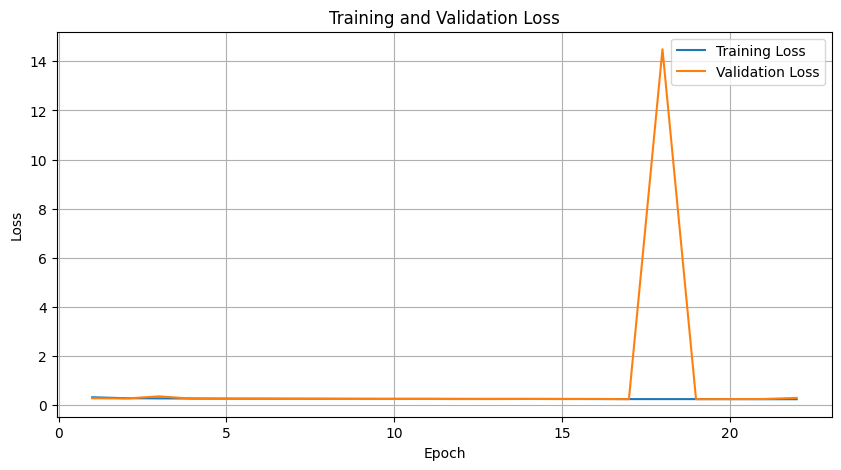

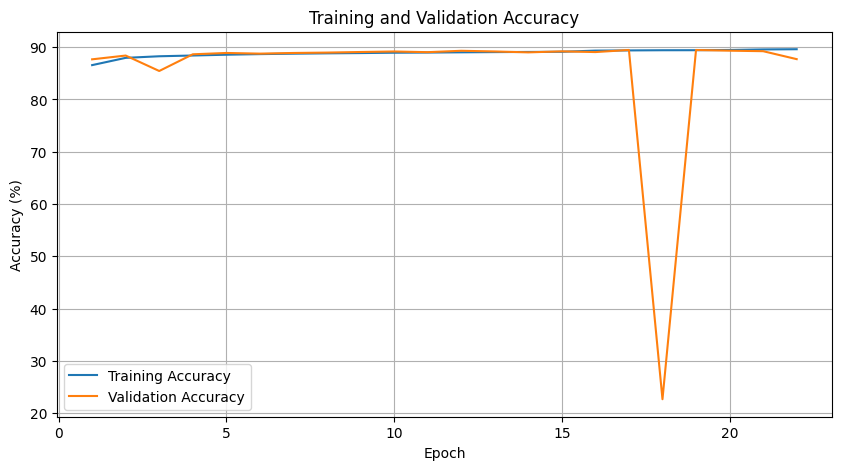

In [ ]:
# ==========================================================
# Section 7: Training Performance Analysis
# Cell 2: Training & Validation Curves
# ==========================================================

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

# ----------------------------------------------------------
# Loss Curve
# ----------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()


# ----------------------------------------------------------
# Accuracy Curve
# ----------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    [x * 100 for x in history["train_accuracy"]],
    label="Training Accuracy"
)

plt.plot(
    epochs,
    [x * 100 for x in history["val_accuracy"]],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# ==========================================================
# Section 7: Training Performance Analysis
# Cell 3: Training Summary
# ==========================================================

import numpy as np

best_epoch = np.argmin(history["val_loss"]) + 1

best_val_loss = history["val_loss"][best_epoch - 1]
best_val_accuracy = history["val_accuracy"][best_epoch - 1]

best_train_loss = history["train_loss"][best_epoch - 1]
best_train_accuracy = history["train_accuracy"][best_epoch - 1]

accuracy_gap = (
    best_train_accuracy - best_val_accuracy
)

print("=" * 60)
print("Training Performance Summary")
print("=" * 60)

print(f"Total Epochs        : {len(history['train_loss'])}")
print(f"Best Epoch          : {best_epoch}")

print("\nBest Epoch Metrics")
print("-" * 60)

print(f"Training Loss       : {best_train_loss:.4f}")
print(f"Validation Loss     : {best_val_loss:.4f}")

print(
    f"Training Accuracy   : "
    f"{best_train_accuracy * 100:.2f}%"
)

print(
    f"Validation Accuracy : "
    f"{best_val_accuracy * 100:.2f}%"
)

print(
    f"Accuracy Gap        : "
    f"{accuracy_gap * 100:.2f}%"
)

print("\nLearning Rate")
print("-" * 60)

print(
    f"Initial LR          : "
    f"{history['learning_rate'][0]:.6f}"
)

print(
    f"Final LR            : "
    f"{history['learning_rate'][-1]:.6f}"
)

print("=" * 60)

Training Performance Summary
Total Epochs        : 22
Best Epoch          : 17

Best Epoch Metrics
------------------------------------------------------------
Training Loss       : 0.2532
Validation Loss     : 0.2495
Training Accuracy   : 89.37%
Validation Accuracy : 89.45%
Accuracy Gap        : -0.09%

Learning Rate
------------------------------------------------------------
Initial LR          : 0.001000
Final LR            : 0.000250


# Section 8

In [ ]:
# ==========================================================
# Section 8: Test Set Evaluation
# Cell 1: Load Best Model
# ==========================================================

BEST_MODEL_PATH = (
    "/content/drive/MyDrive/"
    "Major_Project/models/hybrid_model.pth"
)

print("=" * 60)
print("Loading Best Model")
print("=" * 60)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device
)

model.load_state_dict(checkpoint)

model = model.to(device)

model.eval()

print("Best model loaded successfully.")
print(f"Model path : {BEST_MODEL_PATH}")
print("Model mode : Evaluation")

Loading Best Model
Best model loaded successfully.
Model path : /content/drive/MyDrive/Major_Project/models/hybrid_model.pth
Model mode : Evaluation


In [ ]:
# ==========================================================
# Section 8: Test Set Evaluation
# Cell 2: Generate Test Predictions
# ==========================================================

import numpy as np

model.eval()

all_predictions = []
all_labels = []

print("=" * 60)
print("Generating Test Set Predictions")
print("=" * 60)

with torch.no_grad():

    for inputs, labels in tqdm(
        test_loader,
        desc="Testing"
    ):

        # Move data to GPU
        inputs = inputs.to(
            device,
            non_blocking=True
        )

        # Forward pass
        with torch.cuda.amp.autocast(
            enabled=torch.cuda.is_available()
        ):
            outputs = model(inputs)

        # Predicted class
        predictions = torch.argmax(
            outputs,
            dim=1
        )

        # Store results on CPU
        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )


# Convert to NumPy arrays
all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)


print("\n" + "=" * 60)
print("Test Prediction Completed")
print("=" * 60)

print(f"Test Samples        : {len(all_labels):,}")
print(f"Predictions         : {len(all_predictions):,}")
print(
    f"Correct Predictions : "
    f"{np.sum(all_predictions == all_labels):,}"
)

print(
    f"Test Accuracy       : "
    f"{np.mean(all_predictions == all_labels) * 100:.2f}%"
)

Generating Test Set Predictions


Testing:   0%|          | 0/662 [00:00<?, ?it/s]


Test Prediction Completed
Test Samples        : 338,445
Predictions         : 338,445
Correct Predictions : 302,665
Test Accuracy       : 89.43%


In [ ]:
# ==========================================================
# Section 8: Test Set Evaluation
# Cell 3: Classification Report
# ==========================================================

from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Class names in encoded order
class_names = label_encoder.classes_

# ----------------------------------------------------------
# Classification Report
# ----------------------------------------------------------

report = classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("=" * 80)
print("TEST SET CLASSIFICATION REPORT")
print("=" * 80)

print(report)

# ----------------------------------------------------------
# Overall Metrics
# ----------------------------------------------------------

macro_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

print("=" * 80)
print("SUMMARY METRICS")
print("=" * 80)

print(f"Test Accuracy       : {np.mean(all_predictions == all_labels) * 100:.2f}%")
print(f"Macro Precision     : {macro_precision * 100:.2f}%")
print(f"Macro Recall        : {macro_recall * 100:.2f}%")
print(f"Macro F1-Score      : {macro_f1 * 100:.2f}%")
print(f"Weighted F1-Score   : {weighted_f1 * 100:.2f}%")

TEST SET CLASSIFICATION REPORT
               precision    recall  f1-score   support

       BENIGN     0.9550    0.9738    0.9643       458
    DrDoS_DNS     0.9987    0.9971    0.9979     24513
   DrDoS_LDAP     0.9076    0.9534    0.9300     10697
  DrDoS_MSSQL     0.7940    0.8198    0.8067     21951
    DrDoS_NTP     0.9973    0.9997    0.9985      5966
DrDoS_NetBIOS     0.8188    0.8371    0.8278     19792
   DrDoS_SNMP     0.9933    0.9547    0.9736     25711
   DrDoS_SSDP     0.6668    0.4113    0.5088     12826
    DrDoS_UDP     0.5559    0.6450    0.5971     15452
         LDAP     0.9447    0.9050    0.9244      9355
        MSSQL     0.8577    0.8388    0.8481     27890
      NetBIOS     0.8201    0.8711    0.8448     17558
      Portmap     0.5093    0.1552    0.2378       883
          Syn     0.9762    0.9976    0.9868     27439
         TFTP     0.9992    0.9967    0.9979     97365
          UDP     0.6762    0.7638    0.7173     18930
      UDP-lag     0.9657    0.661

Confusion Matrix
Matrix Shape: (17, 17)


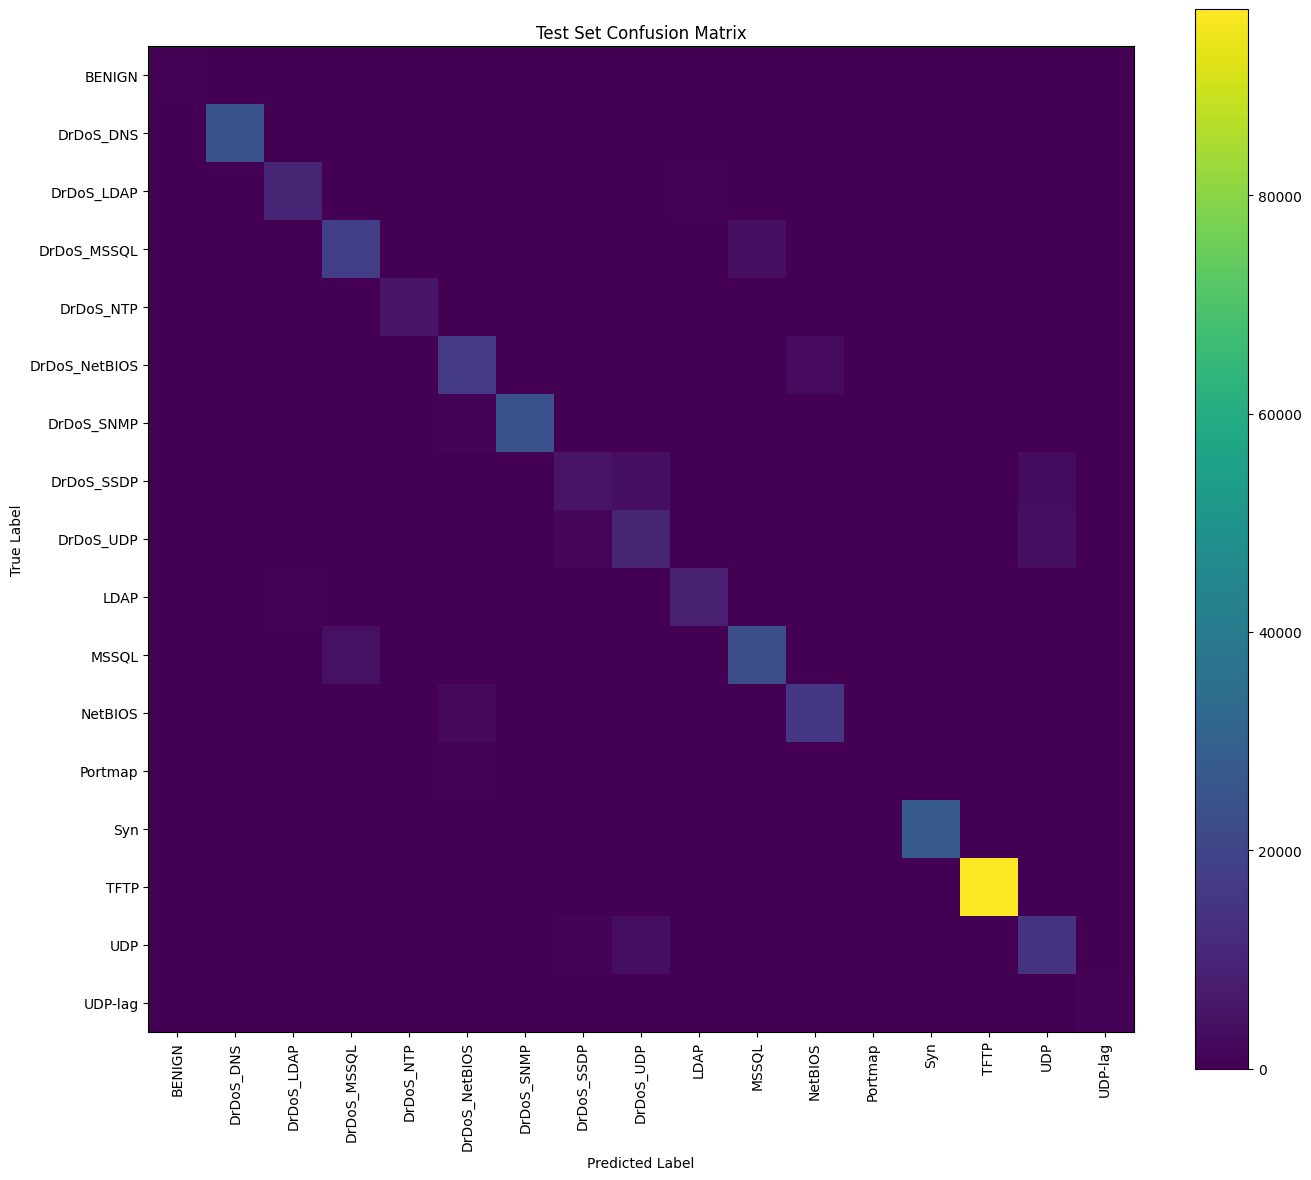

In [ ]:
# ==========================================================
# Section 8: Test Set Evaluation
# Cell 4: Confusion Matrix
# ==========================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=np.arange(len(class_names))
)

print("=" * 60)
print("Confusion Matrix")
print("=" * 60)

print("Matrix Shape:", cm.shape)


# ----------------------------------------------------------
# Plot Confusion Matrix
# ----------------------------------------------------------

plt.figure(figsize=(14, 12))

plt.imshow(cm, interpolation="nearest")

plt.title("Test Set Confusion Matrix")

plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# Section 8: Test Set Evaluation
# Cell 5: Top Confusion Pairs
# ==========================================================

confusion_pairs = cm.copy()

np.fill_diagonal(confusion_pairs, 0)

flat_indices = np.argsort(
    confusion_pairs.ravel()
)[::-1]

print("=" * 80)
print("TOP CONFUSION PAIRS")
print("=" * 80)

shown = 0

for index in flat_indices:

    true_class, predicted_class = np.unravel_index(
        index,
        confusion_pairs.shape
    )

    count = confusion_pairs[
        true_class,
        predicted_class
    ]

    if count == 0:
        break

    print(
        f"{shown + 1:2d}. "
        f"True: {class_names[true_class]:<20} "
        f"→ Predicted: {class_names[predicted_class]:<20} "
        f"| Count: {count:,}"
    )

    shown += 1

    if shown >= 15:
        break

TOP CONFUSION PAIRS
 1. True: MSSQL                → Predicted: DrDoS_MSSQL          | Count: 4,493
 2. True: DrDoS_SSDP           → Predicted: DrDoS_UDP            | Count: 4,152
 3. True: DrDoS_MSSQL          → Predicted: MSSQL                | Count: 3,838
 4. True: UDP                  → Predicted: DrDoS_UDP            | Count: 3,701
 5. True: DrDoS_UDP            → Predicted: UDP                  | Count: 3,649
 6. True: DrDoS_SSDP           → Predicted: UDP                  | Count: 3,246
 7. True: DrDoS_NetBIOS        → Predicted: NetBIOS              | Count: 2,921
 8. True: NetBIOS              → Predicted: DrDoS_NetBIOS        | Count: 2,207
 9. True: DrDoS_UDP            → Predicted: DrDoS_SSDP           | Count: 1,820
10. True: DrDoS_SNMP           → Predicted: DrDoS_NetBIOS        | Count: 934
11. True: LDAP                 → Predicted: DrDoS_LDAP           | Count: 869
12. True: UDP                  → Predicted: DrDoS_SSDP           | Count: 766
13. True: Portmap         

Normalized Confusion Matrix


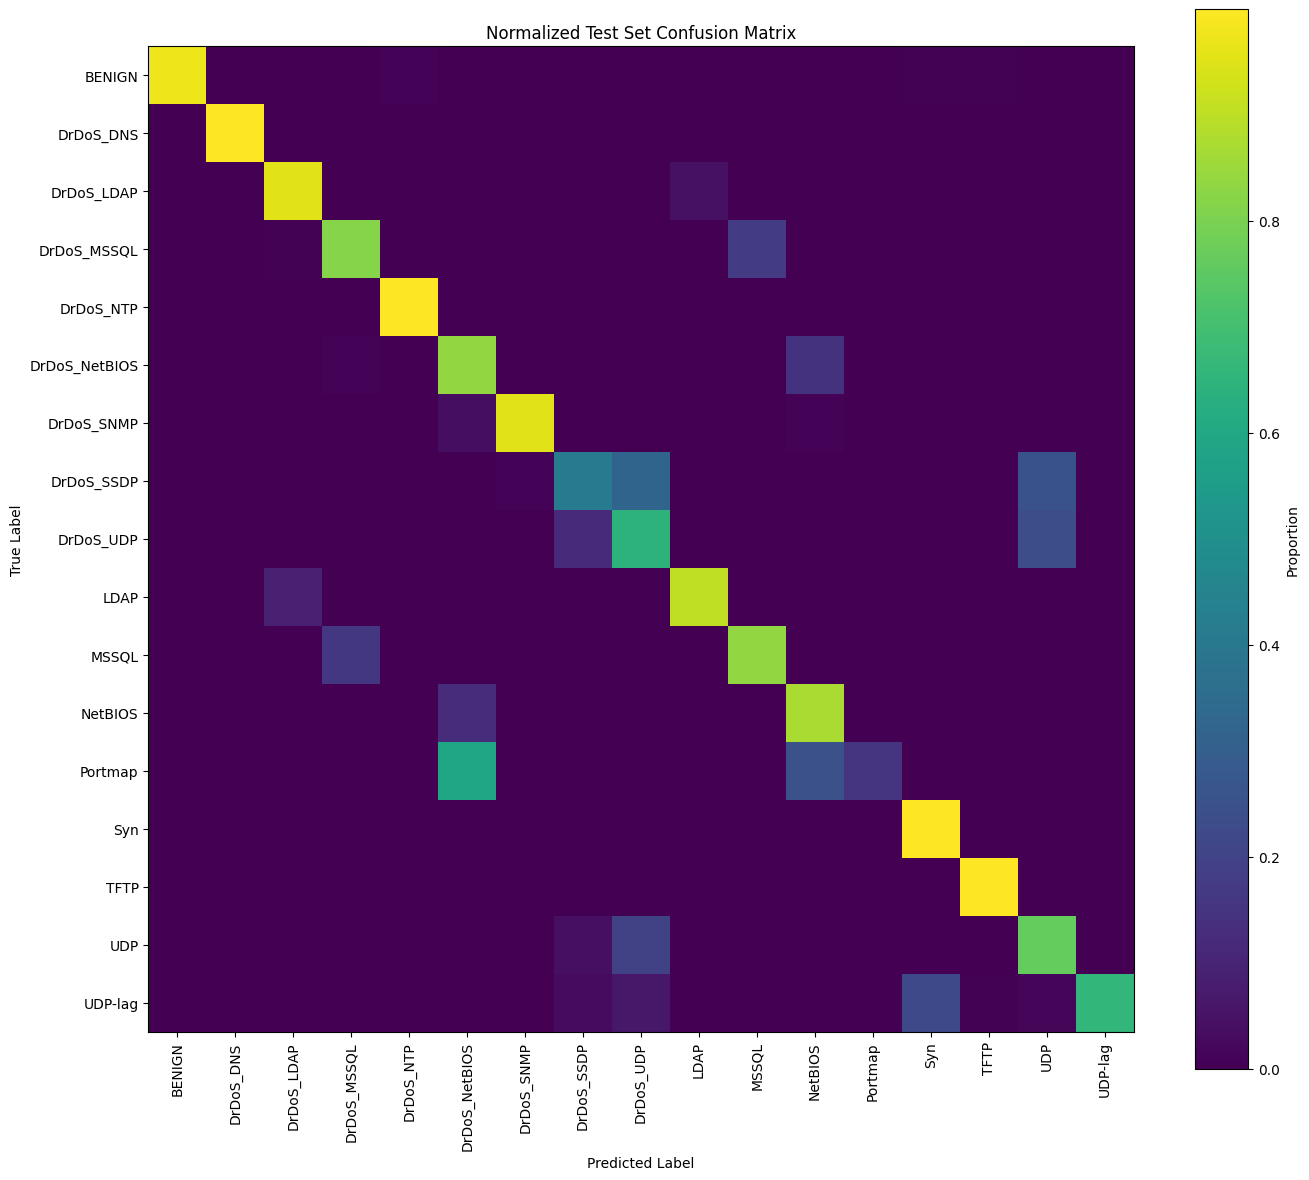

In [ ]:
# ==========================================================
# Section 8: Test Set Evaluation
# Cell 6: Normalized Confusion Matrix
# ==========================================================

# Normalize each row by the true-class total
cm_normalized = (
    cm.astype(np.float64)
    / cm.sum(axis=1, keepdims=True)
)

print("=" * 60)
print("Normalized Confusion Matrix")
print("=" * 60)

plt.figure(figsize=(14, 12))

plt.imshow(
    cm_normalized,
    interpolation="nearest"
)

plt.title(
    "Normalized Test Set Confusion Matrix"
)

plt.colorbar(
    label="Proportion"
)

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# Section 8: Test Set Evaluation
# Cell 7: Save Evaluation Artifacts
# ==========================================================

import json
import numpy as np
from sklearn.metrics import classification_report

EVALUATION_DIR = (
    "/content/drive/MyDrive/"
    "Major_Project/models/evaluation"
)

os.makedirs(EVALUATION_DIR, exist_ok=True)


# ----------------------------------------------------------
# Classification Report
# ----------------------------------------------------------

report_dict = classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)


REPORT_PATH = f"{EVALUATION_DIR}/classification_report.json"

with open(REPORT_PATH, "w") as f:
    json.dump(report_dict, f, indent=4)


# ----------------------------------------------------------
# Confusion Matrix
# ----------------------------------------------------------

CM_PATH = f"{EVALUATION_DIR}/confusion_matrix.npy"

np.save(
    CM_PATH,
    cm
)


# ----------------------------------------------------------
# Normalized Confusion Matrix
# ----------------------------------------------------------

NORMALIZED_CM_PATH = (
    f"{EVALUATION_DIR}/normalized_confusion_matrix.npy"
)

np.save(
    NORMALIZED_CM_PATH,
    cm_normalized
)


# ----------------------------------------------------------
# Summary Metrics
# ----------------------------------------------------------

summary_metrics = {
    "test_accuracy": float(
        np.mean(all_predictions == all_labels)
    ),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1)
}

SUMMARY_PATH = f"{EVALUATION_DIR}/evaluation_summary.json"

with open(SUMMARY_PATH, "w") as f:
    json.dump(summary_metrics, f, indent=4)


print("=" * 60)
print("Evaluation Artifacts Saved")
print("=" * 60)

print(f"Classification Report : {REPORT_PATH}")
print(f"Confusion Matrix      : {CM_PATH}")
print(f"Normalized Matrix     : {NORMALIZED_CM_PATH}")
print(f"Summary Metrics       : {SUMMARY_PATH}")

Evaluation Artifacts Saved
Classification Report : /content/drive/MyDrive/Major_Project/models/evaluation/classification_report.json
Confusion Matrix      : /content/drive/MyDrive/Major_Project/models/evaluation/confusion_matrix.npy
Normalized Matrix     : /content/drive/MyDrive/Major_Project/models/evaluation/normalized_confusion_matrix.npy
Summary Metrics       : /content/drive/MyDrive/Major_Project/models/evaluation/evaluation_summary.json
